# 02 — Model comparison (5-fold CV on the train split)

**Goal:** pick which model family and imbalance strategy is worth tuning in Phase 5.

**Rules followed here** (see `docs/DATA.md`, `docs/ARCHITECTURE.md` D8):
- Only the **train** split is used; the test set is never touched (`compare_models()` discards it).
- 5-fold `StratifiedKFold`, seed 42. Metrics are computed on each validation fold.
- Resampling (SMOTENC) lives *inside* the pipeline, so it only ever sees training folds.
- Hyperparameters are **defaults, not tuned** — this is a fair first look, not a final ranking.
- Class threshold is fixed at 0.5 for recall / precision / F1 (threshold tuning is Phase 5).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt

# Make `import src` work when the notebook runs from notebooks/
ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from src.train import compare_models, format_comparison

print(sys.version.split()[0])

3.11.9


## 1. Run the comparison
`compare_models()` loads and validates the raw data, keeps the train split, cross-validates the five
candidates and saves `reports/model_comparison.csv`. Takes about half a minute.

In [2]:
results = compare_models()
results.round(3)

,pr_auc_mean,pr_auc_std,roc_auc_mean,roc_auc_std,recall_mean,recall_std,precision_mean,precision_std,f1_mean,f1_std
model,,,,,,,,,,
rf_weighted,0.890,0.028,0.973,0.012,0.738,0.055,0.975,0.002,0.839,0.036
xgb_weighted,0.867,0.027,0.971,0.013,0.804,0.033,0.837,0.037,0.820,0.024
xgb_smote,0.845,0.017,0.969,0.008,0.808,0.039,0.621,0.052,0.702,0.046
rf_smote,0.773,0.040,0.974,0.008,0.819,0.030,0.542,0.028,0.651,0.023
logreg_weighted,0.459,0.042,0.923,0.013,0.841,0.046,0.162,0.008,0.271,0.011


In [3]:
# Readable mean ± std table
print(format_comparison(results))

                        pr_auc        roc_auc         recall      precision             f1
model                                                                                     
rf_weighted      0.890 ± 0.028  0.973 ± 0.012  0.738 ± 0.055  0.975 ± 0.002  0.839 ± 0.036
xgb_weighted     0.867 ± 0.027  0.971 ± 0.013  0.804 ± 0.033  0.837 ± 0.037  0.820 ± 0.024
xgb_smote        0.845 ± 0.017  0.969 ± 0.008  0.808 ± 0.039  0.621 ± 0.052  0.702 ± 0.046
rf_smote         0.773 ± 0.040  0.974 ± 0.008  0.819 ± 0.030  0.542 ± 0.028  0.651 ± 0.023
logreg_weighted  0.459 ± 0.042  0.923 ± 0.013  0.841 ± 0.046  0.162 ± 0.008  0.271 ± 0.011


## 2. Chart
PR-AUC (primary metric), recall and precision, with ±1 std across folds as error bars.
The dashed line at PR-AUC = 0.034 is the score of a model with no skill (the failure rate).

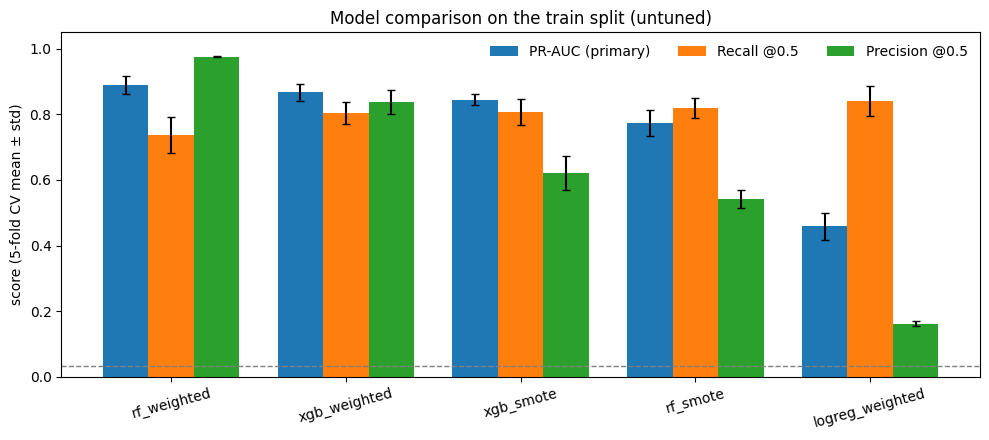

In [4]:
metrics = ["pr_auc", "recall", "precision"]
labels = {"pr_auc": "PR-AUC (primary)", "recall": "Recall @0.5", "precision": "Precision @0.5"}
colors = {"pr_auc": "#1f77b4", "recall": "#ff7f0e", "precision": "#2ca02c"}

fig, ax = plt.subplots(figsize=(10, 4.5))
width = 0.26
x = range(len(results))
for i, m in enumerate(metrics):
    ax.bar(
        [p + (i - 1) * width for p in x],
        results[f"{m}_mean"],
        width,
        yerr=results[f"{m}_std"],
        capsize=3,
        label=labels[m],
        color=colors[m],
    )
ax.axhline(0.034, color="grey", linestyle="--", linewidth=1)
ax.set_xticks(list(x))
ax.set_xticklabels(results.index, rotation=15)
ax.set_ylim(0, 1.05)
ax.set_ylabel("score (5-fold CV mean ± std)")
ax.set_title("Model comparison on the train split (untuned)")
ax.legend(loc="upper right", ncol=3, frameon=False)
fig.tight_layout()
plt.show()

## 3. Interpretation

**Primary metric — PR-AUC.** With only ~3.4 % failures, ROC-AUC is high for every model (0.92–0.97)
and barely separates them; PR-AUC does (0.46 → 0.89). A no-skill model would score ≈ 0.034.

**Ranking by PR-AUC:** `rf_weighted` (0.89) > `xgb_weighted` (0.87) > `xgb_smote` (0.85) >
`rf_smote` (0.77) >> `logreg_weighted` (0.46). The std across folds is 0.02–0.04, so the top two
are close (their gap is about one std) — random forest vs XGBoost is **not** settled by this run.

**Model family.** Both tree ensembles clearly beat logistic regression. The failure modes are
threshold/interaction effects (low power, high strain, small temperature difference), which a linear
model on these features cannot capture; this matches the EDA finding that the engineered features
are not stronger than raw torque *linearly*, but pay off for trees.

**Imbalance strategy.** Class weighting beat SMOTENC for both tree models (RF 0.89 vs 0.77,
XGBoost 0.87 vs 0.85). SMOTE variants reach higher recall at 0.5 but at much lower precision
(0.54–0.62 vs 0.84–0.98): the synthetic minority rows shift probabilities upward, so the 0.5 cut-off
flags many normal samples. That is partly a threshold effect, but PR-AUC is threshold-free and
still prefers class weights, so SMOTE is not worth its extra complexity here.

**Reading recall/precision/F1 with care.** They are at the arbitrary 0.5 threshold. `rf_weighted`
looks precise (0.98) but misses 26 % of failures (recall 0.74); logistic regression finds 84 % of
failures but with 16 % precision. The final operating point is chosen in Phase 5 (recall ≥ 0.85 rule).

**Next (Phase 5):** tune `rf_weighted` and `xgb_weighted` (and keep an eye on the SMOTE variants only
if time allows), select the threshold from out-of-fold predictions, then evaluate once on the test set.

*Caveat:* `scale_pos_weight` for XGBoost is computed from the full train labels, not per fold; with
stratified folds the ratio is practically identical.

## 4. Phase 5 — what was tuned, and why only two models

Only **`rf_weighted`** and **`xgb_weighted`** were tuned. The SMOTE variants (`rf_smote`, `xgb_smote`) and
`logreg_weighted` lost the comparison above (lower PR-AUC), so spending tuning effort on them would not change
the decision. Tuning = `RandomizedSearchCV` (30 candidates, `StratifiedKFold(5)`, `scoring="average_precision"`)
on the **train split only**; the test split is untouched.

The best tuned model by CV PR-AUC (random forest, 0.900 ± 0.022 vs XGBoost 0.881) is refitted on the full train
split. Its decision threshold comes from out-of-fold probabilities: the highest precision among thresholds with
recall >= 0.85 (`docs/DATA.md`, "Threshold rule"). Reaching recall 0.85 was possible and cost precision of about
0.76 (out-of-fold). Tuning and threshold selection reuse the same folds, so these CV numbers are slightly
optimistic; the test set gives the unbiased estimate. Run `python -m src.train` to reproduce.

![Precision and recall vs threshold](../reports/figures/06_threshold_precision_recall.png)


## 5. SHAP interpretation (random forest, train sample)

`TreeExplainer` on the fitted forest, after the pipeline's feature step; values are for the failure class
(probability points).

![SHAP summary](../reports/figures/07_shap_summary.png)
![SHAP importance](../reports/figures/08_shap_importance_bar.png)

- **Power, speed and torque dominate.** `power_w`, `rotational_speed_rpm` and `torque_nm` have the largest mean
  |SHAP|. Low speed and high torque push towards failure; for `power_w` both extremes (very low and very high)
  push towards failure. This matches the EDA regions (low speed + high torque, high speed + low torque) and the
  physics of power failure.
- **Wear and strain add risk when high.** High `tool_wear_min` and `strain` (wear x torque) raise the failure
  probability, in line with the EDA finding that high wear combined with high torque fails often.
- **A small temperature difference raises risk.** Low `temp_diff_k` pushes towards failure (heat dissipation
  failure); the raw air and process temperatures matter much less, because the engineered difference carries
  their signal (EDA: r = 0.88 between them).
- **Product type is weak.** `type_L` nudges risk up and `type_M` / `type_H` down, but the effect is tiny,
  consistent with failure rates of 3.9 / 2.8 / 2.1 % in the EDA.

One nuance: EDA linear correlations ranked torque first and showed no gain from the engineered features, but SHAP
ranks `power_w` and speed higher. That fits EDA insight 7: the engineered features help by capturing interactions
that a linear correlation cannot see.
